# Matplotlib basics — Tips
## 1. Task
Show how restaurant bills and tips are distributed by day and time using basic matplotlib charts.
## 2. Data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns # dataset source

In [2]:
df = sns.load_dataset('tips') # load dataset tips from sns library
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


## histogram

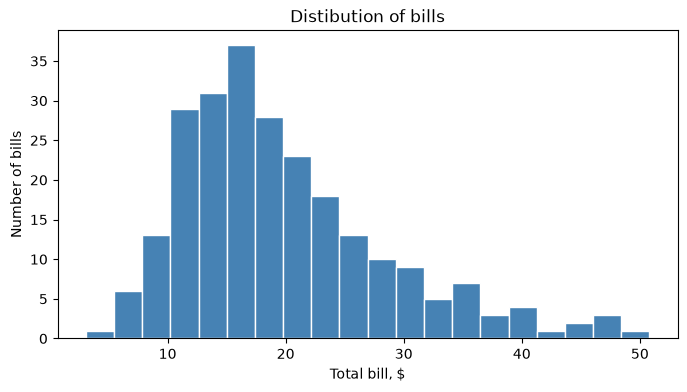

In [4]:
fig, ax = plt.subplots(figsize=(8,4)) # frame 8 x 4

ax.hist(df['total_bill'], bins=20, color='steelblue', edgecolor='white')
ax.set_title('Distibution of bills')
ax.set_xlabel('Total bill, $')
ax.set_ylabel('Number of bills')

plt.show()

## bar chart

day
Thur    2.771452
Fri     2.734737
Sat     2.993103
Sun     3.255132
Name: tip, dtype: float64


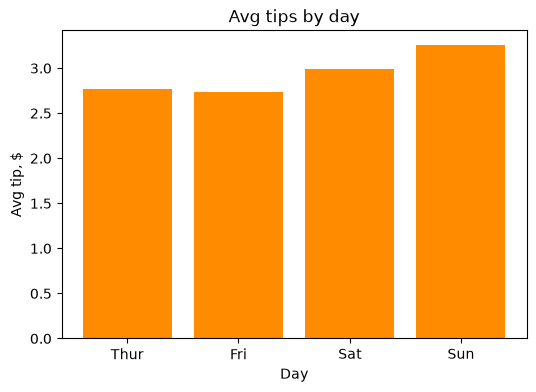

In [5]:
tips_by_day = df.groupby('day', observed=True)['tip'].mean()
print(tips_by_day)

fig, ax = plt.subplots(figsize=(6,4))
ax.bar(tips_by_day.index, tips_by_day.values, color='darkorange')
ax.set_title('Avg tips by day')
ax.set_xlabel('Day')
ax.set_ylabel('Avg tip, $')

plt.show()

## line chart

      total_bill       tip
size                      
1       7.242500  1.437500
2      16.448013  2.582308
3      23.277632  3.393158
4      28.613514  4.135405
5      30.068000  4.028000
6      34.830000  5.225000


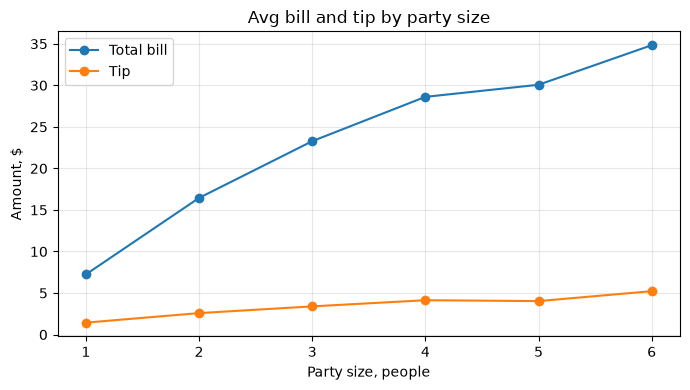

In [6]:
by_size = df.groupby('size')[['total_bill', 'tip']].mean()
print(by_size)

fig, ax = plt.subplots(figsize=(7,4))
ax.plot(by_size.index, by_size['total_bill'], marker='o', label='Total bill')
ax.plot(by_size.index, by_size['tip'], marker='o', label='Tip')

ax.set_title('Avg bill and tip by party size')
ax.set_xlabel('Party size, people')
ax.set_ylabel('Amount, $')
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

## scatter

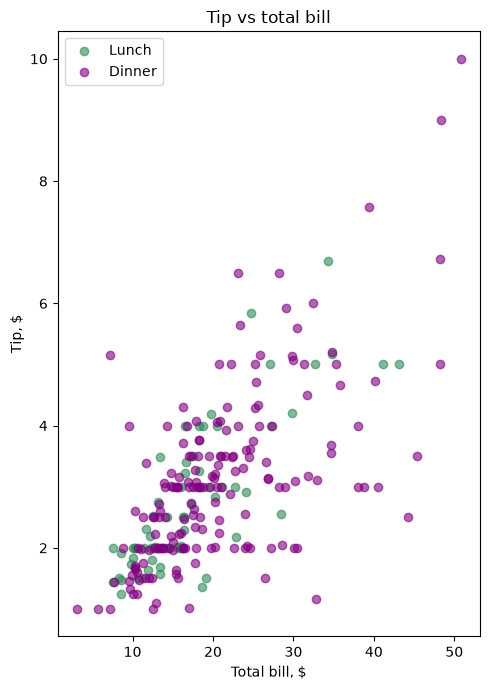

In [7]:
fig, ax = plt.subplots(figsize=(5,7))

for time_value, color in [('Lunch', 'seagreen'), ('Dinner', 'purple')]:
    part = df[df['time'] == time_value]
    ax.scatter(part['total_bill'], part['tip'], color=color, alpha=0.6, label=time_value)

ax.set_title('Tip vs total bill')
ax.set_xlabel('Total bill, $')
ax.set_ylabel('Tip, $')
ax.legend()
fig.tight_layout()

plt.show()

## experiment

day
Thur    16.127563
Fri     16.991303
Sat     15.315172
Sun     16.689729
Name: tip_pct, dtype: float64


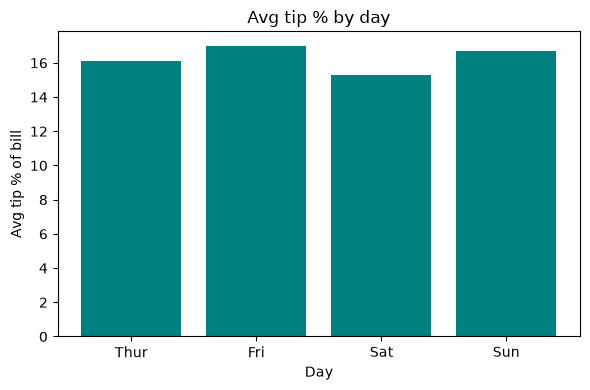

In [8]:
df['tip_pct'] = df['tip'] / df['total_bill'] *100

pct_by_day = df.groupby('day', observed=True)['tip_pct'].mean()
print(pct_by_day)

fig, ax = plt.subplots(figsize=(6,4))
ax.bar(pct_by_day.index, pct_by_day.values, color='teal')
ax.set_title('Avg tip % by day')
ax.set_xlabel('Day')
ax.set_ylabel('Avg tip % of bill')
fig.tight_layout()

plt.show()


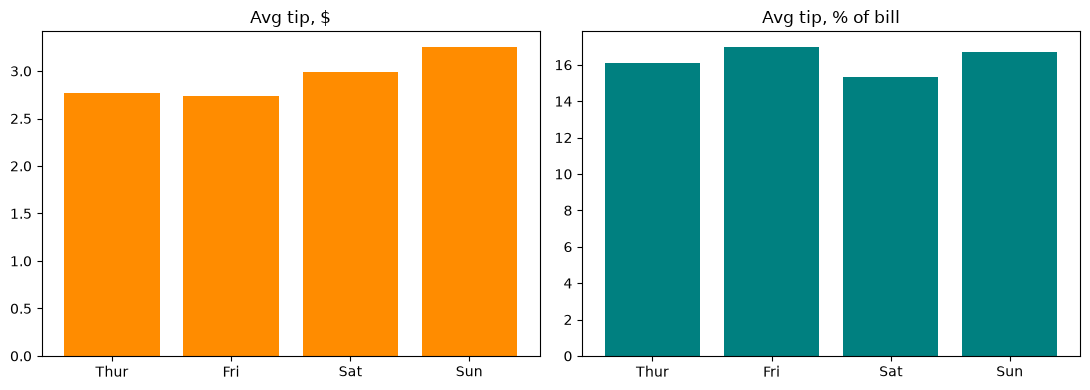

In [9]:
fig, axes = plt.subplots(1,2, figsize=(11,4))

axes[0].bar(tips_by_day.index, tips_by_day.values, color="darkorange")
axes[0].set_title('Avg tip, $')

axes[1].bar(pct_by_day.index, pct_by_day.values, color='teal')
axes[1].set_title('Avg tip, % of bill')

fig.tight_layout()

plt.show()

## What I learned

how to build graphs using matplotlib
- I found out what is fig - figure and ax -axes
- I can build two plots in same figure

types of graohs and what are they best for
- histogram best describes distirbution
- bar chart best describes comparison
- line chart best describes two variables that go together, change along order axis
- scatter plot best describes variation of the variables, their relationship

comparing two metrics side by side shows how data may be misleading